# DNS Caching: A Hash Table in the Wild

Every time you open a website, your device has to turn a name such as `wikipedia.org` into an IP address like `203.0.113.7`. That translation is done by the so-called **Domain Name System (DNS)**, and it happens so often that the whole internet would feel sluggish without **caching**. Under the hood, a DNA cache is a textbook **hash table**: a key (the domain name, such as `wikipedia.org`) maps to a value (the IP address).

In this notebook you will:

| Part | What you do |
| -----|-------------|
| 0 | Understand what DNS is and why it caches |
| 1 | Build a **hash table from scratch** and visualise buckets, collisions and resizing |
| 2 | Build a **DNS cache** on top of it, with TTL (expiry) |
| 3 | Simulate **realistic traffic** and watch the cache warm up |
| 4 | Run **experiments**: how do TTL and cache size change performance? |
| 5 | Prove **why a hash table** beats a list |
| 6 | Poke at **real DNS** on your own machine |
| 7 | Real-world nuances |

## 0. Background: what DNS does and why it caches

Computers talk to each other with numeric IP addresses, but people prefer names. DNS is the internet's phone book.

Looking up a name **from scratch** (a "cold" lookup) can involve several network round trips:

```
Your device ──▶ recursive resolver (your ISP, or 1.1.1.1, or 8.8.8.8)
                     │
                     ├──▶ root server           "Who handles .org?"
                     ├──▶ TLD server (.org)     "Who handles wikipedia.org?"
                     └──▶ authoritative server  "wikipedia.org is at <IP address>"
```

Each hop costs milliseconds, so a cold lookup typically takes **tens to hundreds of milliseconds**. A single web page can need dozens of different names (images, scripts, fonts, ads, analytics...), so repeating this work every time would be painfully slow, and it would also hammer the authoritative servers.

**The fix is caching.** Answers are remembered at many layers: your browser, your operating system, your home router and your ISP's resolver.

Every DNS answer comes with a **TTL (Time To Live)**: the number of seconds the owner of the domain says the answer may be reused. After the TTL runs out, the cached entry must be thrown away and fetched again. This lets website owners move servers without clients being stuck on old addresses forever.

**Where does the hash table come in?** A DNS cache is basically a key-value store:

```
key   = "wikipedia.org"
value = ("203.0.113.7", expires_at = 1735689600.0)
```

The cache is consulted on *every single query*, so lookups must be extremely fast no matter how many names are stored. A hash table gives **O(1) average-time** lookups, which is exactly why many resolvers keep their caches in hash-based structures.

## Setup

We import a few standard tools:

* `hashlib` gives us a stable hash function.
* `OrderedDict` is a hash table that also remembers insertion order.
* `numpy` and `matplotlib`

We also fix the random seeds so you get the same results every time you run the notebook.

In [2]:
import time
import random
import hashlib
from collections import OrderedDict

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch

random.seed(42)
np.random.seed(42)

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

print("Setup complete.")

Setup complete.


---
## Part 1. A hash table from scratch
Before we build a DNA cache, let us understand the data structure underneath it.

### The core idea in three steps
1. **Hash function.** Turn the key (a string like `"github.com"`) into a big integer. The same key must *always* give the same number, and different key should *usually* give different numbers.
2. **Modulo.** Compute `number % num_buckets` to get a bucket index between `0` and `num_buckets - 1`.
3. **Look in that one bucket.** To find a key later, hash it again, jump straight to its bucket and look only there. No scanning through everything else.

### Collisions
Two different keys can land in the same bucket; this is called a **collision**. It is unavoidable (there are far more possible keys than buckets), so every hash table needs a strategy for it. We use **separate chaining**: each bucket holds a small list of `(key, value)` pairs.

### Load factor and resizing
The **load factor** is `items / buckets`. If it climbs too high, chains get long and lookups slow down, because we are back to scanning lists. So when the load factor passes a threshold (we use 0.75), the table **doubles its numbers of buckets and re-inserts every item** (called *rehashing*). This is rare, so on average operations stay O(1).

### A note on `hash()` vs `haslib`
Python's built-in `hash()` for strings is deliberately **randomized on every run** (to stop attackers from crafting keys that all collide). That would make our demos change each time, so we use `md5` from `hashlib` instead. We are using it purely to scatter keys evenly, not for security.

In [4]:
class SimpleHashTable:
    """A tiny hash table using separate chaining, written for learning."""

    def __init__(self, num_buckets=8, max_load_factor=0.75):
        self.num_buckets = num_buckets
        self.max_load_factor = max_load_factor      # None = never resize
        self.buckets = [[] for _ in range(num_buckets)]
        self.size = 0

    # --- step 1: the hash function ---
    @staticmethod
    def _hash(key):
        digest = hashlib.md5(key.encode()).hexdigest()      # 32 hex characters
        return int(digest, 16)      # as a big integer

    # --- step 2: turn the big number into a bucket index ---
    def _index(self, key):
        return self._hash(key) % self.num_buckets

    # --- the three operations ---
    def put(self, key, value):
        bucket = self.buckets[self._index(key)]
        for i, (existing_key, _) in enumerate(bucket):
            if existing_key == key:     # key already there: overwrite
                bucket[i] = (key, value)
                return
        bucket.append((key, value))     # new key: add to the chain
        self.size += 1
        if self.max_load_factor and self.load_factor > self.max_load_factor:
            self._resize()

    def get(self, key, default=None):
        bucket = self.buckets[self._index(key)]     # jump straight to ONE bucket
        for existing_key, value in bucket:
            if existing_key == key:
                return value
        return default

    def delete(self, key):
        bucket = self.buckets[self._index(key)]
        for i, (existing_key, _) in enumerate(bucket):
            if existing_key == key:
                del bucket[i]
                self.size -= 1
                return True
        return False

    # --- housekeeping ---
    @property
    def load_factor(self):
        return self.size / self.num_buckets

    def _resize(self):
        old_items = [pair for bucket in self.buckets for pair in bucket]
        self.num_buckets *= 2
        self.buckets = [[] for _ in range(self.num_buckets)]
        self.size = 0
        for key, value in old_items:        # rehash everything
            self.put(key, value)

    def __len__(self):
        return self.size

    def __contains__(self, key):
        return self.get(key, default=None) is not None


# Quick sanity check
t = SimpleHashTable()
t.put("example.com", "192.0.2.1")
print(t.get("example.com"), "|", t.get("missing.com"), "|", len(t))

192.0.2.1 | None | 1


**What to notice in the code:**
* `get()` never looks at the whole table. It computes one bucket index and scans only that chain. That is the whole trick.
* `put()` on an existing key *overwrites* it. A DNS cache needs this to refresh a record.
* `_resize()` collects all items, doubles the buckets and re-inserts them. We have to re-insert (not just copy) because `hash % num_buckets` changes when `num_buckets` changes.

### Where does each domain end up?
Let us hash twelve well-known domains into **8 buckets** (resizing switched off, so we can see collisions clearly). Because 12 items cannot fit 8 buckets without sharing, at least some collisions are guaranteed.

In [8]:
domains = [
    "google.com", "wikipedia.org", "github.com", "example.com",
    "python.org", "openai.com", "anthropic.com", "bbc.co.uk",
    "nytimes.com", "reddit.com", "netflix.com", "amazon.com",
]

demo = SimpleHashTable(num_buckets=8, max_load_factor=None)     # No resizing

print(f"{'domain':<16} {'hash (first 12 hex digits)':<28} bucket (= hash % 8)")
print("-" * 70)
for i, d in enumerate(domains):
    h = demo._hash(d)
    print(f"{d:<16} {format(h, '032x')[:12]:<28} {h % 8}")
    demo.put(d, f"192.0.2.{i + 1}")     # 192.0.2.x is reserved for documentation

domain           hash (first 12 hex digits)   bucket (= hash % 8)
----------------------------------------------------------------------
google.com       1d5920f4b44b                 2
wikipedia.org    465f7f8831e4                 6
github.com       99cd2175108d                 4
example.com      5ababd603b22                 2
python.org       db0fe87d2a44                 2
openai.com       4047152196ff                 5
anthropic.com    26c12df3ba9e                 4
bbc.co.uk        ca19e0b76e13                 1
nytimes.com      1b3726503af8                 0
reddit.com       1fd7de7da0fc                 5
netflix.com      084b9a35bf7a                 0
amazon.com       a2a828386438                 6


Now let us **draw** the table. Each row is a bucket. Domains in the same bucket are linked in a chain.
* Green = alone in its bucket (the ideal case: found in one step)
* Orange = shares a bucket with others (a collision: we must scan the chain)

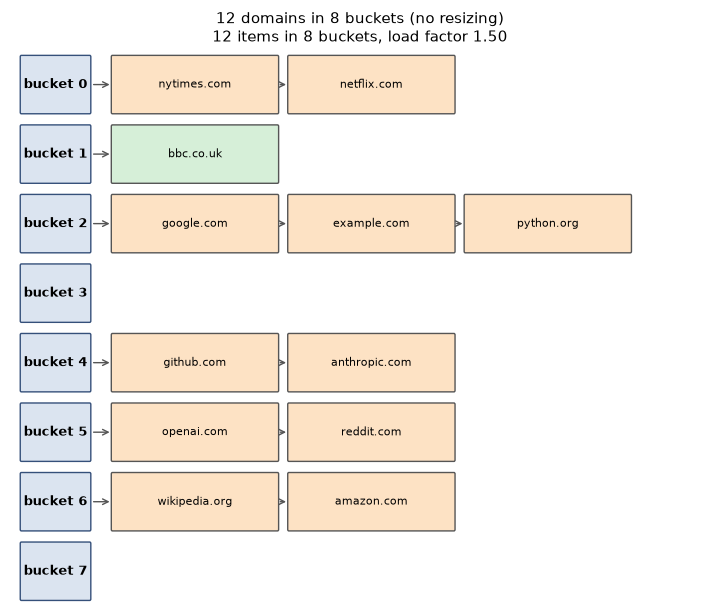

In [9]:
def draw_hash_table(table: SimpleHashTable, title="Hash table", max_items_per_row=5):
    """Draw every bucket as a row, with its chain of keys to the right."""
    n = table.num_buckets
    cols = max(1, min(max_items_per_row, max(len(b) for b in table.buckets)))
    fig, ax = plt.subplots(figsize=(1.6 + 0.9 * cols + 3, 0.62 * n + 1.3))

    for i, bucket in enumerate(table.buckets):
        y = n - 1 - i
        # the bucket label
        ax.add_patch(FancyBboxPatch((0, y + 0.1), 1.2, 0.8, boxstyle="round,pad=0.02",
                                    fc="#dbe4f0", ec="#35507a"))
        ax.text(0.6, y + 0.5, f"bucket {i}", ha="center", va="center",
                fontsize=9, fontweight="bold")

        colour = "#fde2c4" if len(bucket) > 1 else "#d6efd8"
        for j, (key, _) in enumerate(bucket[:max_items_per_row]):
            x = 1.6 + j * 3.1
            ax.add_patch(FancyBboxPatch((x, y + 0.1), 2.9, 0.8, boxstyle="round,pad=0.02",
                                        fc=colour, ec="#555"))
            ax.text(x + 1.45, y + 0.5, key, ha="center", va="center", fontsize=8)
            ax.annotate("", xy=(x, y + 0.5), xytext=(x - 0.38 if j == 0 else x - 0.2, y + 0.5),
                        arrowprops=dict(arrowstyle="->", color="#555"))
        if len(bucket) > max_items_per_row:
            ax.text(1.6 + cols * 3.1, y + 0.5,
                    f"+{len(bucket) - max_items_per_row} more", va="center", fontsize=8)

    ax.set_xlim(-0.2, 1.6 + cols * 3.1 + 1.2)
    ax.set_ylim(0, n)
    ax.axis("off")
    ax.set_title(f"{title}\n{table.size} items in {table.num_buckets} buckets, "
                 f"load factor {table.load_factor:.2f}", fontsize=11)
    plt.tight_layout()
    plt.show()

draw_hash_table(demo, "12 domains in 8 buckets (no resizing)")

### Resizing in action
Now let us insert **1,000** domains into two tables:
* **Fixed**: 64 buckets, never resizes. The load factor ends up around 15, so chains are long.
* **Growing**: starts with 8 buckets, doubles whenever the load factor passes 0.75.

The histograms show how many buckets hold 0, 1, 2, 3... items. Short chains mean fast lookups.

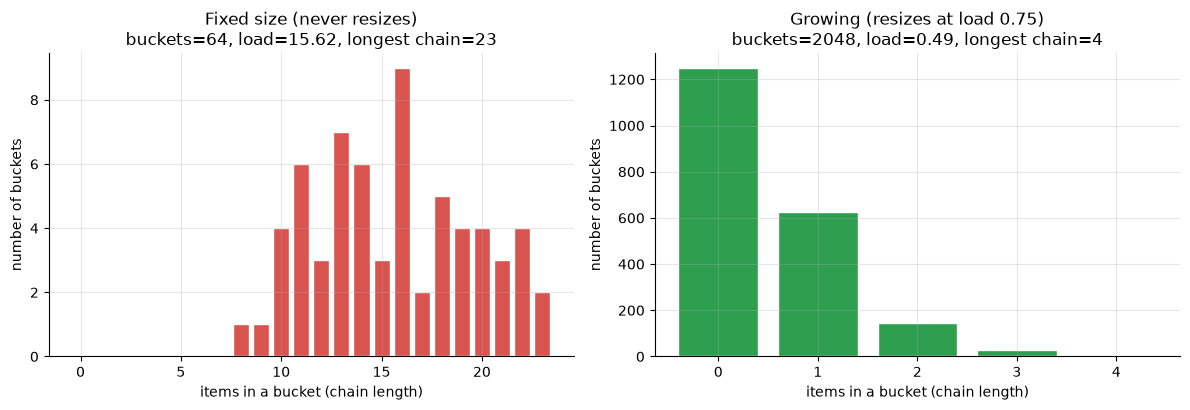

In [10]:
def make_domains(n):
    return [f"site{i}.example.com" for i in range(n)]

def chain_length_histogram(ax, table: SimpleHashTable, title, colour):
    lengths = [len(b) for b in table.buckets]
    counts = np.bincount(lengths)
    ax.bar(range(len(counts)), counts, color=colour, edgecolor="white")
    ax.set_title(f"{title}\nbuckets={table.num_buckets}, load={table.load_factor:.2f}, "
                 f"longest chain={max(lengths)}")
    ax.set_xlabel("items in a bucket (chain length)")
    ax.set_ylabel("number of buckets")

fixed = SimpleHashTable(num_buckets=64, max_load_factor=None)
growing = SimpleHashTable(num_buckets=8, max_load_factor=0.75)
for i, d in enumerate(make_domains(1000)):
    fixed.put(d, i)
    growing.put(d, i)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
chain_length_histogram(axes[0], fixed, "Fixed size (never resizes)", "#d9534f")
chain_length_histogram(axes[1], growing, "Growing (resizes at load 0.75)", "#2e9e4f")
plt.tight_layout()
plt.show()

**Reading the plot:** the fixed table has buckets holding anywhere from about 8 to 23 items (average around 15), so each lookup scans a long chain. The growing table keeps most buckets empty or holding one or two items, so each lookup touches only a handful. Resizing trades a bit of memory for speed.

Notice the bell-shaped spread on the left: that is a good hash function at work, distributing keys evenly. Next, let us see what happens when the hash function is **bad**.

### What if the hash function is bad?
A hash function's job is to *scatter* keys. Here is a deliberately terrible one: it uses only the **length** of the domain name. Lots of domains have the same length, so they all pile into the same few buckets.

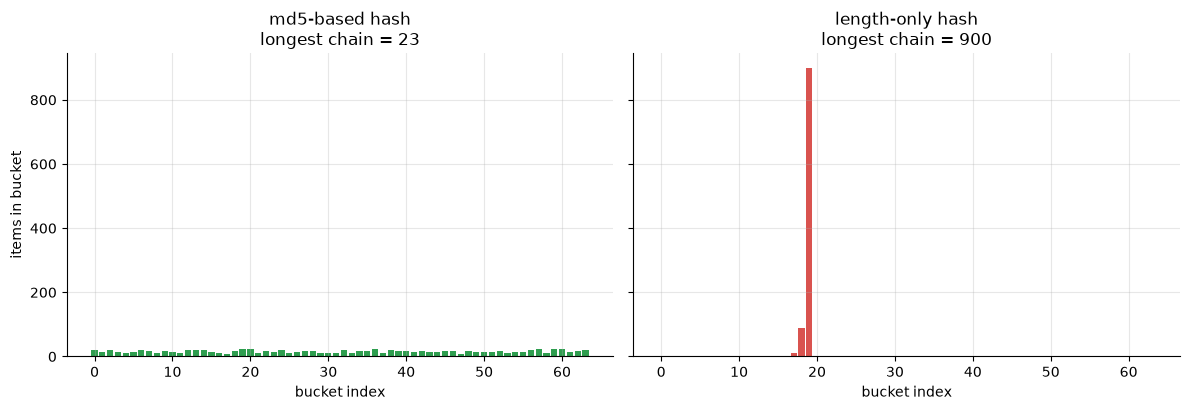

In [11]:
class BadHashTable(SimpleHashTable):
    """Same table, terrible hash function: just the length of the key."""
    def _hash(self, key):
        return len(key)

good = SimpleHashTable(num_buckets=64, max_load_factor=None)
bad = BadHashTable(num_buckets=64, max_load_factor=None)
for i, d in enumerate(make_domains(1000)):
    good.put(d, i)
    bad.put(d, i)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, table, title, colour in [(axes[0], good, "md5-based hash", "#2e9e4f"),
                                 (axes[1], bad, "length-only hash", "#d9534f")]:
    sizes = [len(b) for b in table.buckets]
    ax.bar(range(len(sizes)), sizes, color=colour)
    ax.set_title(f"{title}\nlongest chain = {max(sizes)}")
    ax.set_xlabel("bucket index")
axes[0].set_ylabel("items in bucket")
plt.tight_layout()
plt.show()

With the bad hash only **three** buckets are used (the names are 17, 18, or 19 characters long), and one of them holds 900 of the 1,000 items. The table has degraded into a "few long lists", and the O(1) promise is gone. Resizing would not rescue it either, because the hash values themselves are clumped.

**Takeaway:** a hash table is only as a good as its hash function. A good one makes the "average O(1)" promise come true.

---

# Part 2. Building a DNS cache